In [2]:
import pandas as pd
import matplotlib.pyplot as plt

filename = r"exoplanets_slim_2026-11-3.csv"

df = pd.read_csv(
    filename,
    header=0
)

# making columns titles more readable
df = df.rename(columns={
    "pl_name": "pl_name",
    "hostname": "host_name",

    "sy_snum": "sys_num_star",
    "sy_pnum": "sys_num_planet",
    "sy_dist": "sys_dist_e",

    "discoverymethod": "disc_method",
    #"disc_year": "",
    #"disc_facility": "",

    #"pl_controv_flag": "",
    "pl_eqt": "pl_temp",
    "pl_insol": "pl_insol_flux",

    "pl_orbper": "pl_orb_period",
    "pl_orbeccen": "pl_orb_eccen",
    "pl_orbsmax": "pl_orb_semimajor_axis",

    "pl_rade": "pl_radius_e",
    "pl_bmasse": "pl_mass_e",
    "pl_bmassprov": "pl_mass_prov",

    "st_teff": "st_temp",
    "st_rad": "st_radius",
    #"st_mass": "",
    "st_met": "st_metal",
    "st_logg": "st_gravity",
    #"st_age": "",
    })

print(df.shape)
display(df.dtypes)

(6451, 23)


pl_name                      str
host_name                    str
sys_num_star               int64
sys_num_planet             int64
sys_dist_e               float64
disc_method                  str
disc_year                  int64
disc_facility                str
pl_controv_flag            int64
pl_temp                  float64
pl_insol_flux            float64
pl_orb_period            float64
pl_orb_eccen             float64
pl_orb_semimajor_axis    float64
pl_radius_e              float64
pl_mass_e                float64
pl_mass_prov                 str
st_temp                  float64
st_radius                float64
st_mass                  float64
st_metal                 float64
st_gravity               float64
st_age                   float64
dtype: object

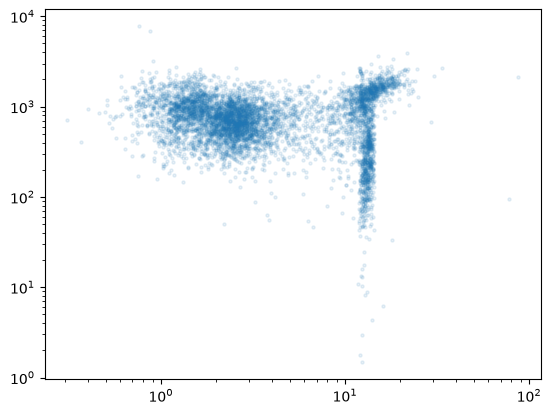

In [3]:
x = df["pl_radius_e"]
y = df["pl_temp"]

p = plt.figure()
plt.yscale("log")
plt.xscale("log")
plt.scatter(x, y, alpha=0.1, s=5)

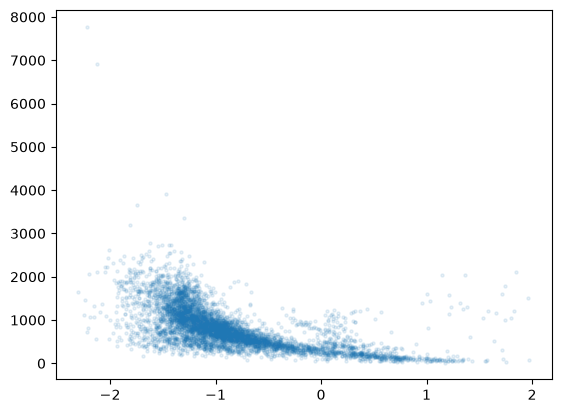

In [10]:
import numpy as np
removeOutliers = df["pl_orb_semimajor_axis"] < 100.0
d = df[removeOutliers]
d["smaxis_log"] = np.log10(df["pl_orb_semimajor_axis"])
x = d["smaxis_log"]
y = d["pl_temp"]

p = plt.figure()
#plt.xscale("log")
plt.scatter(x, y, alpha=0.1, s=5)

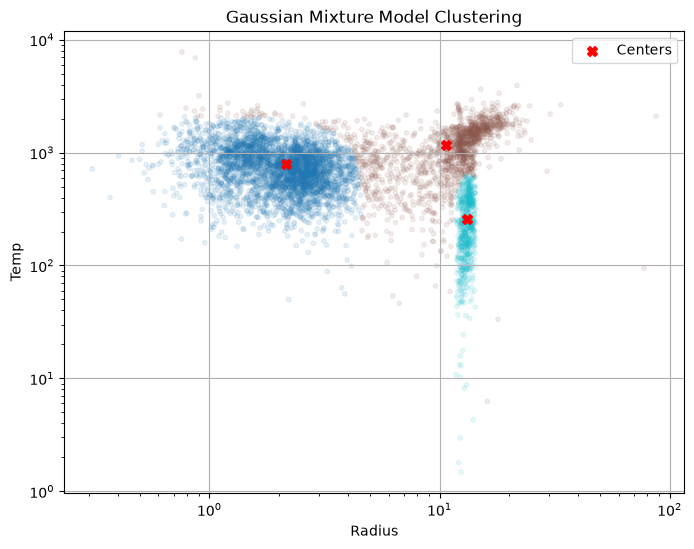

In [50]:
from sklearn.mixture import GaussianMixture

d = df[["pl_radius_e", "pl_temp"]].dropna()

# Select both features for the 2D GMM tracking
X = d[["pl_radius_e", "pl_temp"]].values

y = d["pl_temp"]

gmm = GaussianMixture(
    n_components=3,
    covariance_type='full',
    random_state=42
)

gmm.fit(X)
labels = gmm.predict(X)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=10, alpha=0.1)

plt.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    s=50,
    c='red',
    marker='X',
    label='Centers'
)

plt.title("Gaussian Mixture Model Clustering")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Radius")
plt.ylabel("Temp")
plt.grid(True)
plt.legend()
plt.show()

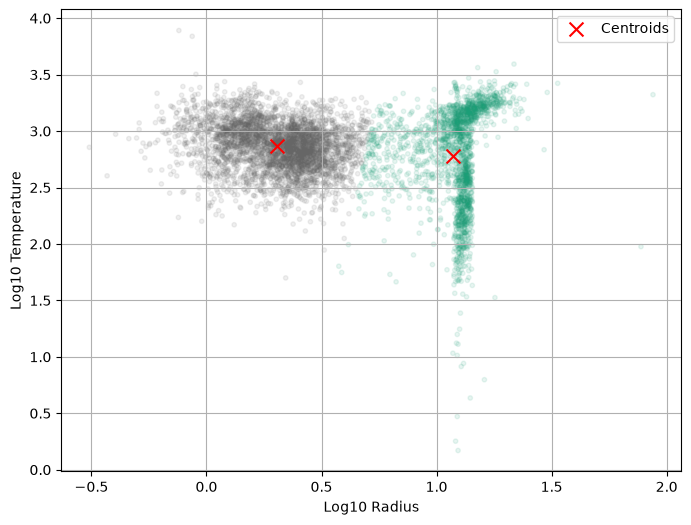

Silhouette Score: 0.5357852165120376
Davies-Bouldin Score: 0.8218008657353852
Calinski-Harabasz Score: 6388.503295867018


In [59]:
import numpy as np
from scipy.cluster.vq import kmeans2
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

data = np.log10(d[["pl_radius_e", "pl_temp"]].values)

centroids, clusters = kmeans2(data, 2, minit='++')

plt.figure(figsize=(8, 6))

plt.scatter(
    data[:, 0],
    data[:, 1],
    c=clusters,
    cmap='Dark2',
    s=10,
    alpha=0.1
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='red',
    marker='x',
    s=100,
    label='Centroids'
)

plt.xlabel("Log10 Radius")
plt.ylabel("Log10 Temperature")
plt.grid(True)
plt.legend()
plt.show()

print("Silhouette Score:", silhouette_score(data, clusters))
print("Davies-Bouldin Score:", davies_bouldin_score(data, clusters))
print("Calinski-Harabasz Score:", calinski_harabasz_score(data, clusters))